# Lab 2 — Artificial Neurons (Perceptron, Bias, Activations)

This lab builds intuition for **artificial neurons**, focusing on:

- A manual perceptron for the AND logic gate,
- How **bias** shifts a decision boundary,
- Implementing and plotting **activation functions**,
- Comparing **activations** within a small Keras model,
- A short **reflection** tying it together.

**Workflow note:** Work directly in Colab with GPU off (CPU is fine for Week 3). Commit back to your own GitHub repo frequently via **File → Save a copy to GitHub**.


[![Open In Colab]([![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Nathnael6/DeepLearning_CSB410_Labs_MegaFolder/blob/main/Lab2/lab2.ipynb)
**Note:** Replace `username`, `repo`, and `path-to-file` above with your own GitHub username, repository name, and the exact path to this file in your repo.


**Name:** Nathnael Yirga  
**Course:** CSB 410 — Deep Learning  
**Lab:** 2 — Artificial Neurons

## B.1 Manual Perceptron (NumPy)


In [5]:

# Goal: implement a single perceptron to model the AND logic gate.
# Instructions:
# 1) Import NumPy.
# 2) Implement a step(z) activation that returns 1 where z >= 0 and 0 otherwise.
# 3) Create input data X with four rows: [0,0], [0,1], [1,0], [1,1]. dtype float32.
# 4) Create target labels y = [0, 0, 0, 1] as int32.
# 5) Choose weights w (length-2 NumPy array) and a bias scalar b for AND logic.
#    Hint: equal weights (e.g., 1.0, 1.0) and a negative bias (e.g., -1.5) will require both inputs to be 1.
# 6) Compute z = X @ w + b   (vectorized for all 4 samples).
# 7) Compute y_hat = step(z).
# 8) Print z, y_hat, and y to verify correctness.
#
# Expected output:
# - z: an array of four values (weighted sums), with only the last one >= 0
# - y_hat: [0 0 0 1]
# - y:     [0 0 0 1]

# Write your code below.

import numpy as np

# Define the step activation function
def step(z):
    return np.where(z >= 0, 1, 0)

# Create the four possible AND gate inputs
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=np.float32)

# Define the correct AND gate outputs
y = np.array([0, 0, 0, 1], dtype=np.int32)

# Choose weights and a negative bias
w = np.array([1.0, 1.0])
b = -1.5

# Calculate the weighted sums
z = X @ w + b

# Apply the step activation to get predictions
y_hat = step(z)

# Print the results
print("z:", z)
print("y_hat:", y_hat)
print("y:", y)


z: [-1.5 -0.5 -0.5  0.5]
y_hat: [0 0 0 1]
y: [0 0 0 1]


## B.2 Bias Intuition


In [7]:

# Goal: observe how changing the bias shifts the decision boundary.
# Instructions:
# 1) Reuse your X, w from B.1 (or recreate them quickly).
# 2) Create a list of bias values, e.g., [-2.0, -1.5, -1.0, -0.5, 0.0].
# 3) For each bias in the list, compute y_hat = step(X @ w + b) and print the result.
# 4) Briefly note which biases make the perceptron stricter or looser (in a markdown cell below).
#
# Expected output:
# - Each line should show the bias value and predicted outputs (array of length 4).
# - Example:
#   b=-2.0: [0 0 0 0]
#   b=-1.5: [0 0 0 1]
#   b=-1.0: [0 0 1 1]
#   ...
# - This should demonstrate how lowering the bias makes it easier for the perceptron to activate.

# Write your code below.

# Create a list of different bias values
bias_values = [-2.0, -1.5, -1.0, -0.5, 0.0]

# Test each bias using the same inputs and weights from B.1
for b in bias_values:
    y_hat = step(X @ w + b)
    print(f"b={b:.1f}: {y_hat}")


b=-2.0: [0 0 0 1]
b=-1.5: [0 0 0 1]
b=-1.0: [0 1 1 1]
b=-0.5: [0 1 1 1]
b=0.0: [1 1 1 1]


Changing the bias affects how easily the perceptron activates. so when the bias is more negative, like -2.0 or -1.5, the perceptron gets stricter because it needs both both inputs to be 1 before producing an output of 1. As the bias increases toward 0, the perceptron becomes less strict and starts producing 1 even when only one input is active. This shows us that how the bias shifts the decision boundary without changing the weights.

## B.3 Activation Functions: Implement & Plot


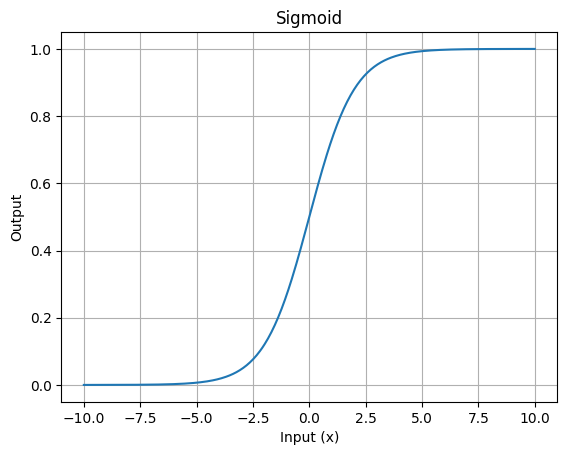

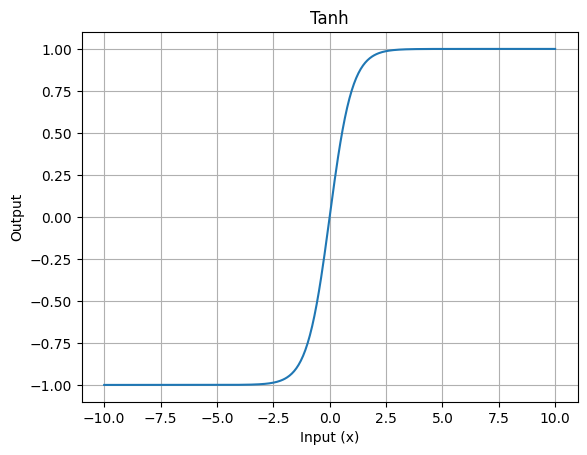

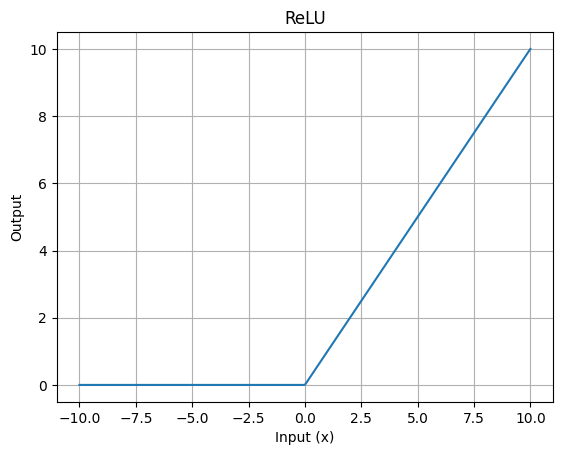

In [8]:

# Goal: implement three activation functions (without importing from ML frameworks) and plot them.
# Instructions:
# 1) Import NumPy and matplotlib.pyplot as plt.
# 2) Implement functions:
#       sigmoid(x) -> 1/(1+exp(-x))
#       tanh(x)    -> use np.tanh(x)
#       relu(x)    -> elementwise max(0, x)
#    Each function should accept scalars or NumPy arrays and return a NumPy array.
# 3) Create an array xs = np.linspace(-10, 10, 400).
# 4) Make three separate plots (one for each activation). Do not customize colors.
# 5) Add simple titles: "Sigmoid", "Tanh", "ReLU".
#
# Expected output:
# - Three plots:
#   1) Sigmoid: S-shaped curve from ~0 to ~1.
#   2) Tanh: S-shaped curve from ~-1 to ~1, crossing at (0,0).
#   3) ReLU: Flat at 0 for x<0, linearly increasing for x>0.

# Write your code below.

import numpy as np
import matplotlib.pyplot as plt

# Define the Sigmoid activation function
def sigmoid(x):
    return np.asarray(1 / (1 + np.exp(-np.asarray(x))))

# Define the Tanh activation function
def tanh(x):
    return np.asarray(np.tanh(x))

# Define the ReLU activation function
def relu(x):
    return np.asarray(np.maximum(0, x))

# Generate 400 values between -10 and 10
xs = np.linspace(-10, 10, 400)

# Plot Sigmoid
plt.figure()
plt.plot(xs, sigmoid(xs))
plt.title("Sigmoid")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.grid(True)
plt.show()

# Plot Tanh
plt.figure()
plt.plot(xs, tanh(xs))
plt.title("Tanh")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.grid(True)
plt.show()

# Plot ReLU
plt.figure()
plt.plot(xs, relu(xs))
plt.title("ReLU")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.grid(True)
plt.show()


## B.4 Swap Activations in a Keras Model (MNIST)


In [9]:

# Goal: compare the impact of different hidden-layer activations on MNIST with a shallow network.
# Instructions:
# 1) Import TensorFlow/Keras:
#       from tensorflow import keras
#       from tensorflow.keras import layers
# 2) Load MNIST using keras.datasets.mnist.load_data().
# 3) Normalize pixel values to [0,1] and flatten images to vectors of length 784.
# 4) Write a helper function train_with_activation(act: str) that:
#       - Builds a Sequential model: Input(784) -> Dense(128, activation=act) -> Dense(10, activation='softmax')
#       - Compiles with Adam(1e-3), sparse_categorical_crossentropy, metrics=['accuracy']
#       - Fits for a small number of epochs (e.g., epochs=3, batch_size=128, validation_split=0.1)
#       - Evaluates on the test set and returns the test accuracy (float).
# 5) Loop over activations ['sigmoid', 'tanh', 'relu']:
#       - Call the helper for each activation
#       - Print the test accuracy for each
# 6) In a short markdown cell below, summarize what you observe and provide a hypothesis why.
#
# Expected output:
# - Three lines printed (one per activation), e.g.:
#   sigmoid -> test acc: 0.92
#   tanh    -> test acc: 0.94
#   relu    -> test acc: 0.97
# - ReLU is typically highest, but exact numbers will vary.

# Write your code below.

# Import TensorFlow and Keras
from tensorflow import keras
from tensorflow.keras import layers

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values from [0,255] to [0,1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 28x28 image into 784 values
x_train = x_train.reshape((x_train.shape[0], 784))
x_test = x_test.reshape((x_test.shape[0], 784))

# Function to build, train, and evaluate a model
def train_with_activation(act: str):

    # Create a neural network using the selected activation
    model = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(128, activation=act),
        layers.Dense(10, activation="softmax")
    ])

    # Compile the model using Adam optimizer
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train the model for 3 epochs
    model.fit(
        x_train,
        y_train,
        validation_split=0.1,
        epochs=3,
        batch_size=128,
        verbose=0
    )

    # Evaluate accuracy using the test dataset
    test_loss, test_acc = model.evaluate(
        x_test, y_test, verbose=0
    )

    return float(test_acc)

# Compare three different activation functions
activations = ["sigmoid", "tanh", "relu"]

# Store accuracy results for comparison
results = {}

for act in activations:
    accuracy = train_with_activation(act)
    results[act] = accuracy
    print(f"{act:7s} -> test acc: {accuracy:.4f}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
sigmoid -> test acc: 0.9385
tanh    -> test acc: 0.9554
relu    -> test acc: 0.9669


## B.5 Reflection (Short Answer)

- Which activation performed best in your experiment? Did that match your expectation?
- How does the bias term affect the decision boundary in your perceptron example?
- When might you prefer sigmoid, tanh, or ReLU in hidden layers? Explain briefly.


### Observations

After training the three models on the MNIST dataset, I observed that ReLU performed the best with a test accuracy of 96.69%, followed by Tanh at 95.54% and Sigmoid at 93.85%. And yes this satisfied my expectations beacause thay ReLu's perform better because they generaly help meural networks to learn effieciently by avoiding some of the gradient problems that we instead would have found in the sigmoid and TanH and Hence why the sigmoid also performed poorly, its gradient becomes very small when the activations saturates in which in return slows down learning.
Also I would prefer ReLU in most hidden layers because it is simple, trains efficiently. Sigmoid might be useful when we want values between 0 and 1, although it can slow down learning when the gradients become very small. Tanh can be useful when we want outputs between -1 and 1 because it is centered around zero, which can sometimes help training. Based on my experiment, I would choose ReLU for a model like MNIST because it achieved the highest accuracy of 96.69%.